# 3 · Umbral por costo, ganancia acumulada, SHAP, prueba temporal y API

**Supuestos explícitos** (en `config.py`, fáciles de cambiar):

| Supuesto | Valor | De dónde sale |
|---|---:|---|
| Costo por cliente gestionado | 8 USD | 2,6 llamadas promedio por cliente × ~3 USD (≈ 5 min de agente con cargas + telefonía) |
| Beneficio por depósito | 80 USD | depósito de 5.000 USD a 1 año × 1,6 % de margen neto de intereses |

Con probabilidad **calibrada** p, llamar conviene si `p × 80 − 8 > 0`, es decir **p > 10 %**.

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
warnings.filterwarnings("ignore")
RAIZ = Path.cwd().parent
sys.path.insert(0, str(RAIZ / "src")); sys.path.insert(0, str(RAIZ))
from campana import config, datos, modelos, explicar, evaluacion as ev
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
pd.set_option("display.width", 140)

In [2]:
import joblib
paquete = joblib.load(RAIZ / "models" / "modelo_campana.joblib")
modelo, calibrador, umbral = paquete["modelo"], paquete["calibrador"], paquete["umbral"]
df = datos.cargar()
ent, pru = datos.particion_estratificada(df)
Xp, yp = datos.X_y(pru)
p = calibrador.transform(modelos.probabilidad(modelo, Xp))
print(f"umbral teórico {ev.umbral_teorico():.3f} · umbral elegido con validación cruzada {umbral:.3f}")

umbral teórico 0.100 · umbral elegido con validación cruzada 0.110


## 3.1 Ganancia según el umbral

El umbral se eligió maximizando la ganancia en las predicciones **fuera de pliegue** del entrenamiento (11 %), muy cerca del teórico (10 %): otra señal de que las probabilidades están bien calibradas.

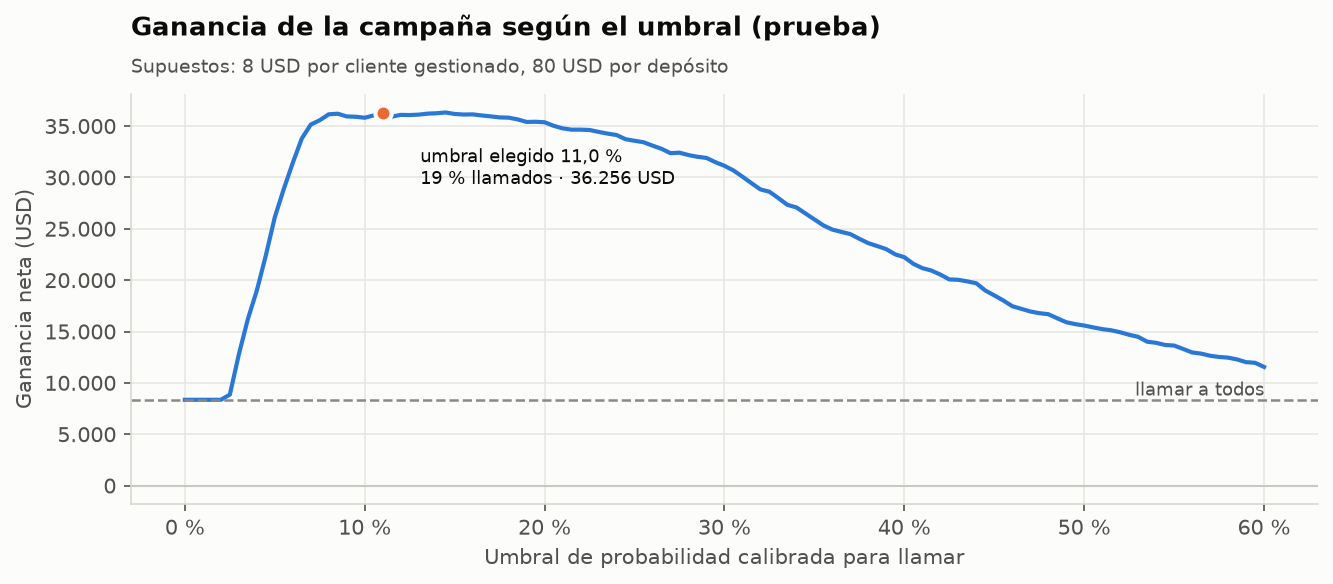

In [3]:
display(Image(RAIZ / "reports" / "figures" / "04_ganancia_umbral.png"))

In [4]:
pol = pd.read_csv(RAIZ / "reports" / "politicas_prueba.csv", index_col=0)
pol[["llamadas", "pct_llamados", "exitos", "pct_exitos_capturados", "conversion_pct", "ganancia", "ganancia_por_1000"]]

,llamadas,pct_llamados,exitos,pct_exitos_capturados,conversion_pct,ganancia,ganancia_por_1000
politica,,,,,,,
No llamar a nadie,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
Llamar a todos,"8,236.0000",100.0000,928.0000,100.0000,11.2700,"8,352.0000","1,014.0800"
Regla: segmentos con tasa > 10 %,"5,279.0000",64.1000,784.0000,84.4800,14.8500,"20,488.0000","2,487.6200"
"Logística calibrada, p ≥ umbral","1,705.0000",20.7000,601.0000,64.7600,35.2500,"34,440.0000","4,181.6400"
"LightGBM calibrado, p ≥ umbral (FINAL)","1,548.0000",18.8000,608.0000,65.5200,39.2800,"36,256.0000","4,402.1400"
Capacidad limitada: top 20 % del modelo,"1,648.0000",20.0100,613.0000,66.0600,37.2000,"35,856.0000","4,353.5700"
Oráculo (solo quienes suscriben),928.0000,11.2700,928.0000,100.0000,100.0000,"66,816.0000","8,112.6800"


**Llamando al 19 % de los clientes se consigue el 66 % de los depósitos**, con una conversión de 39 % (vs 11 % al llamar a todos). La ganancia en prueba pasa de **8.352 a 36.256 USD** (×4,3) y de 4.402 USD por cada 1.000 clientes.

### Sensibilidad a los supuestos
Si cambian los costos, el umbral cambia (`costo / beneficio`) **sin re-entrenar** — es la ventaja de tener probabilidades calibradas.

In [5]:
pd.read_csv(RAIZ / "reports" / "sensibilidad_costos.csv")

,costo,beneficio,umbral,pct_llamados,ganancia_modelo,ganancia_todos,mejora_vs_todos
0,4.0000,40.0000,0.1000,20.2000,"17,904.0000","4,176.0000","13,728.0000"
1,4.0000,80.0000,0.0500,58.9400,"45,544.0000","41,296.0000","4,248.0000"
2,4.0000,160.0000,0.0200,98.7500,"115,308.0000","115,536.0000",-228.0000
3,8.0000,40.0000,0.2000,14.4400,"12,928.0000","-28,768.0000","41,696.0000"
4,8.0000,80.0000,0.1000,20.2000,"35,808.0000","8,352.0000","27,456.0000"
5,8.0000,160.0000,0.0500,58.9400,"91,088.0000","82,592.0000","8,496.0000"
6,16.0000,40.0000,0.4000,6.8100,"4,384.0000","-94,656.0000","99,040.0000"
7,16.0000,80.0000,0.2000,14.4400,"25,856.0000","-57,536.0000","83,392.0000"
8,16.0000,160.0000,0.1000,20.2000,"71,616.0000","16,704.0000","54,912.0000"


Solo cuando la llamada es muy barata frente al margen (4 USD vs 160 USD → umbral 2,5 %) conviene llamar prácticamente a todos y el modelo no agrega valor. En los demás escenarios el modelo gana, y cuanto más cara la llamada, más.

## 3.2 Ganancia acumulada y lift (si el call center tiene capacidad limitada)

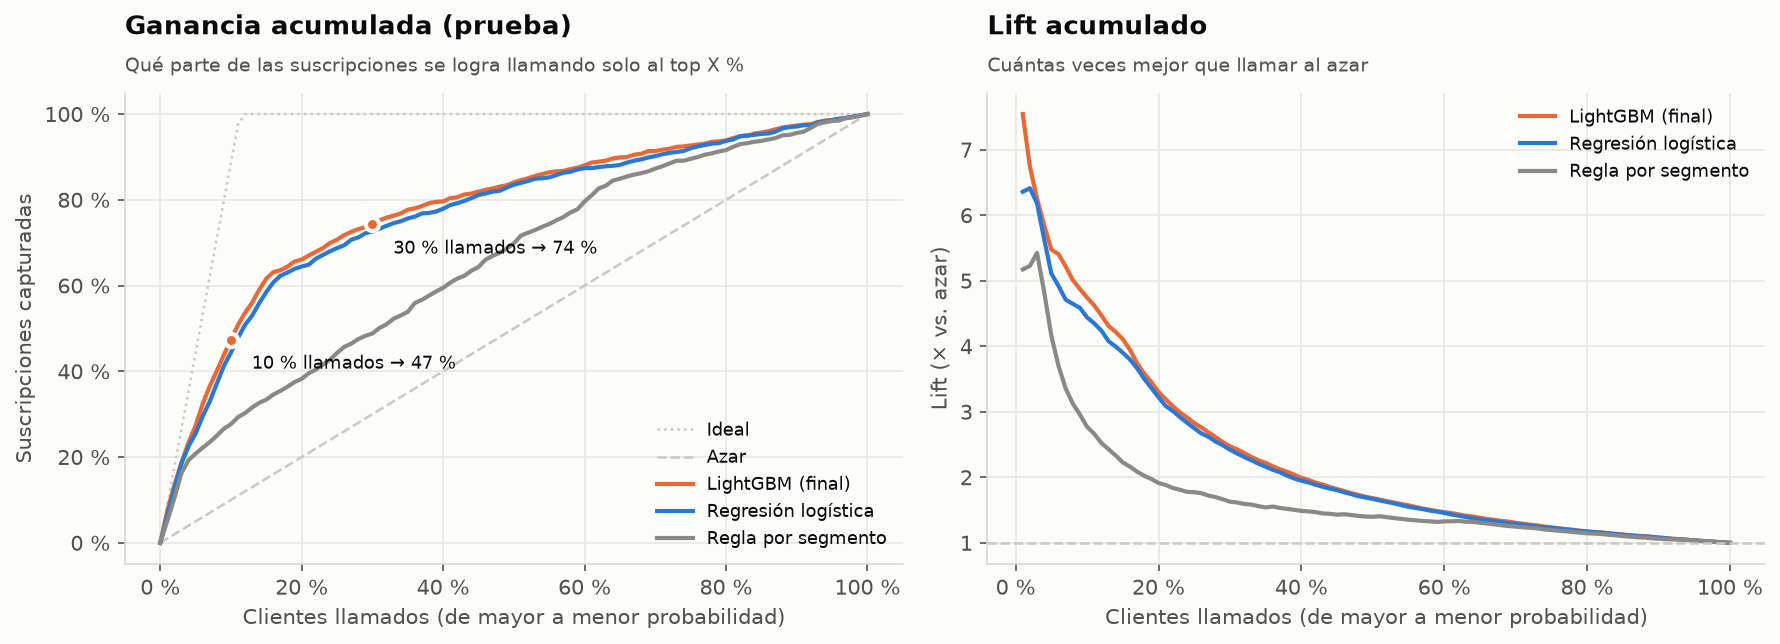

,clientes,suscripciones,prob_media,tasa_real,pct_capturado_acum,lift
decil,,,,,,
1,824,440,0.5127,0.5340,47.4138,4.7391
2,824,173,0.1957,0.2100,66.0560,1.8633
3,823,76,0.0837,0.0923,74.2457,0.8196
4,824,50,0.0677,0.0607,79.6336,0.5385
5,823,41,0.0595,0.0498,84.0517,0.4421
6,824,37,0.0525,0.0449,88.0388,0.3985
7,823,31,0.0469,0.0377,91.3793,0.3343
8,824,23,0.0406,0.0279,93.8578,0.2477
9,823,32,0.0332,0.0389,97.3060,0.3451


In [6]:
display(Image(RAIZ / "reports" / "figures" / "05_ganancia_acumulada.png"))
ev.tabla_deciles(yp, p)

## 3.3 Interpretabilidad con SHAP

TreeSHAP nativo de LightGBM (exacto). Los efectos están en log-odds del modelo antes de calibrar; la calibración es monótona y no cambia el orden ni el signo.

In [7]:
muestra = Xp.sample(3000, random_state=config.SEMILLA)
imp = explicar.importancia(modelo, muestra)
imp.head(10)

,variable,shap_medio_abs,etiqueta
0,num_empleados,0.2907,Nº de empleados (economía)
1,euribor_3m,0.1747,Euríbor 3 meses
2,tipo_contacto,0.1607,Tipo de teléfono
3,mes,0.1343,Mes del contacto
4,var_empleo,0.1199,Variación del empleo
5,edad,0.0566,Edad
6,dia_semana,0.0538,Día de la semana
7,dias_desde_contacto,0.0472,Días desde el último contacto
8,ipc,0.0472,Índice de precios (IPC)
9,resultado_previo,0.0436,Resultado campaña anterior


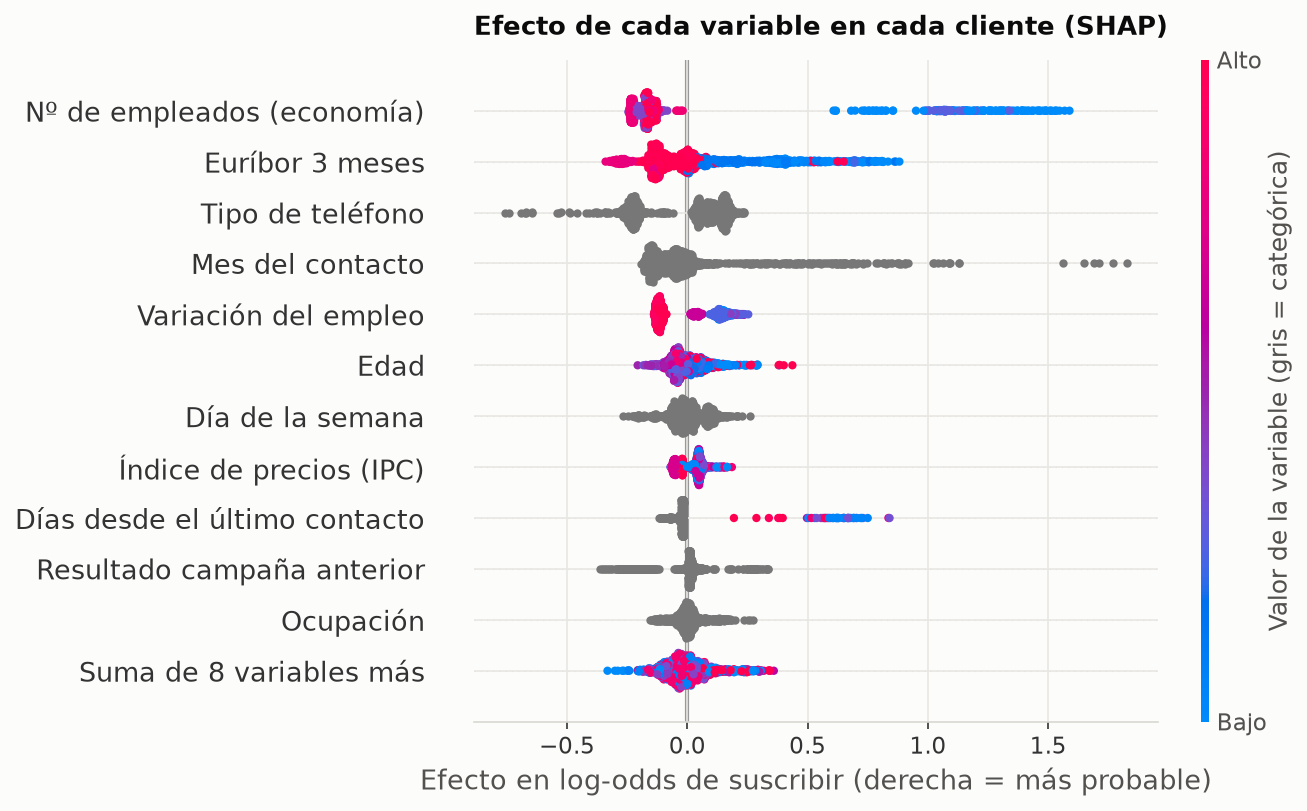

In [8]:
display(Image(RAIZ / "reports" / "figures" / "07_shap_beeswarm.png"))

- **La economía manda**: con pocos empleados en la economía y euríbor bajo (2009–2010) la probabilidad sube mucho. Un depósito a plazo atrae cuando otras opciones rinden poco… y también cuando el banco seleccionó mejor a quién llamar.
- **Celular** > teléfono fijo.
- **Mes**: marzo, septiembre, octubre y diciembre aparecen como «buenos meses», pero en gran parte es el **régimen** (esos meses casi solo existen en 2009–2010). Por eso hay que tener cuidado al leer el mes como estacionalidad.
- **Historia con el cliente**: quien fue contactado hace pocos días en una campaña anterior (y sobre todo con éxito) tiene mucha más probabilidad.

### Explicación de un cliente

probabilidad calibrada: 77.5%


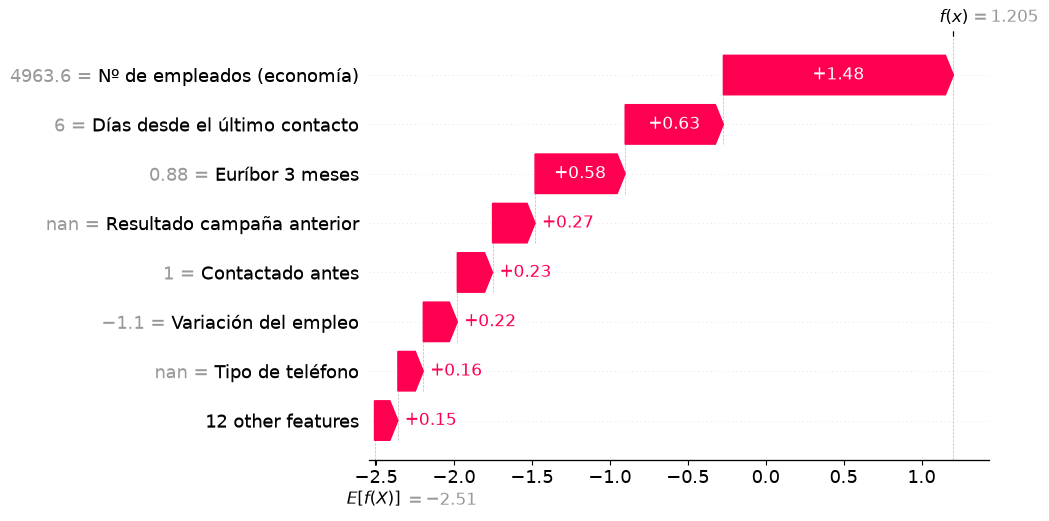

In [9]:
import shap
fila = Xp[(Xp["resultado_previo"] == "success")].head(1)
exp = explicar.explicacion_shap(modelo, fila)
print(f"probabilidad calibrada: {calibrador.transform(modelos.probabilidad(modelo, fila))[0]:.1%}")
shap.plots.waterfall(exp[0], max_display=8)

## 3.4 Prueba de estrés temporal

Entrenar con todo lo anterior a **mayo 2009** (30,4 mil clientes, 6 % de éxito) y predecir **2009-05 → 2010-11** (10,8 mil clientes, 25 % de éxito). Se comparan tres formas de operar:
- **modelo fijo**: se entrena una vez;
- **recalibrar** cada mes: se corrige solo el intercepto con las etiquetas de los 3 meses anteriores;
- **re-entrenar** cada mes con todo lo conocido hasta el mes anterior.

In [10]:
import json
t = json.loads((RAIZ / "reports" / "resultados.json").read_text(encoding="utf-8"))["temporal"]
pd.DataFrame({
    "AUC": [t["auc"], t["auc"], t["auc_reentrenado"], None],
    "Brier": [t["brier_fijo"], t["brier_recalibrado"], t["brier_reentrenado"], None],
    "% llamados": [t["pct_llamados_fijo"], t["pct_llamados_recalibrado"], t["pct_llamados_reentrenado"], 100],
    "ganancia USD": [t["ganancia_fijo"], t["ganancia_recalibrado"], t["ganancia_reentrenado"], t["ganancia_todos"]],
}, index=["modelo fijo", "recalibrado cada mes", "re-entrenado cada mes", "llamar a todos"])

,AUC,Brier,% llamados,ganancia USD
modelo fijo,0.7040,0.1949,21.0600,"80,120.0000"
recalibrado cada mes,0.7040,0.1732,41.1715,"126,496.0000"
re-entrenado cada mes,0.7894,0.1491,46.1274,"137,112.0000"
llamar a todos,NaN,NaN,100.0000,"132,520.0000"


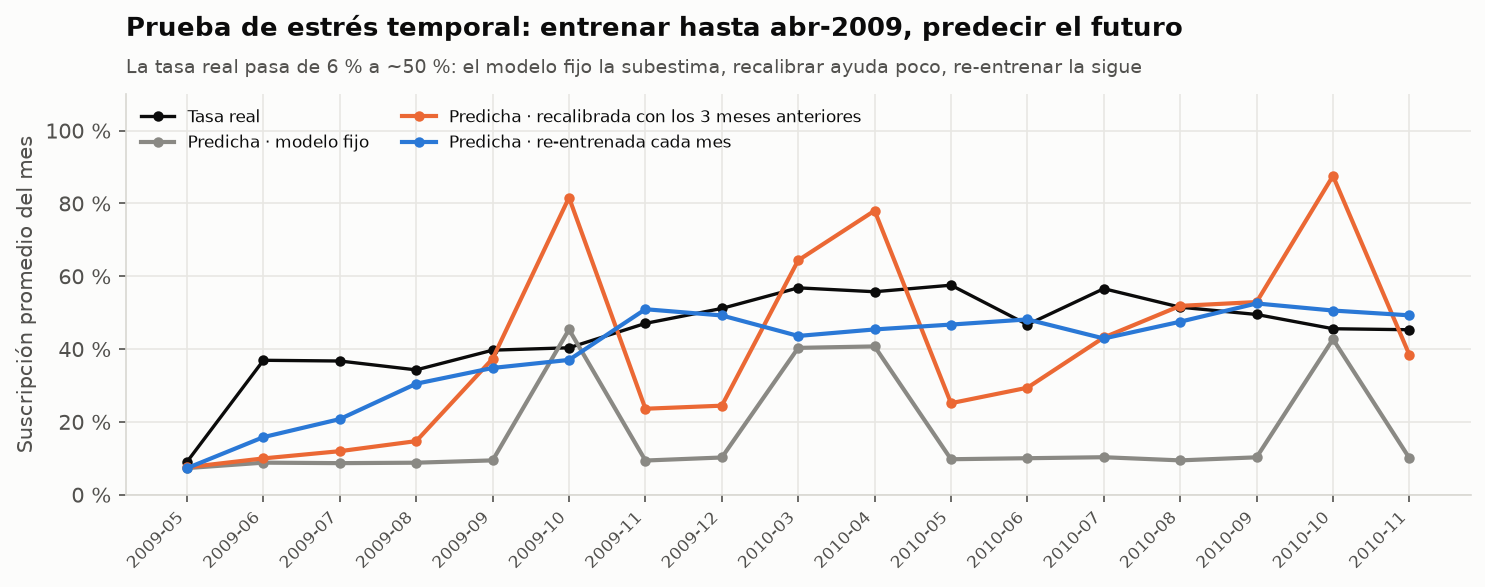

,periodo,n,tasa_real,prob_sin_recalibrar,prob_recalibrada,prob_reentrenado,auc_fijo,auc_reentrenado
0,2009-05,5793,0.0905,0.0732,0.0752,0.0730,0.5861,0.5861
1,2009-06,715,0.3692,0.0881,0.0997,0.1582,0.5821,0.5957
2,2009-07,177,0.3672,0.0867,0.1196,0.2077,0.5362,0.5556
3,2009-08,770,0.3429,0.0879,0.1472,0.3049,0.5995,0.5993
4,2009-09,267,0.3970,0.0943,0.3735,0.3482,0.6661,0.6572
5,2009-10,446,0.4036,0.4538,0.8162,0.3703,0.5740,0.5955
6,2009-11,357,0.4706,0.0939,0.2361,0.5095,0.6610,0.6768
7,2009-12,172,0.5116,0.1023,0.2446,0.4923,0.6136,0.6236
8,2010-03,264,0.5682,0.4033,0.6438,0.4361,0.6895,0.6827
9,2010-04,174,0.5575,0.4073,0.7802,0.4540,0.6735,0.6165


In [11]:
display(Image(RAIZ / "reports" / "figures" / "08_prueba_temporal.png"))
pd.read_csv(RAIZ / "reports" / "prueba_temporal_mensual.csv")

**Lectura honesta:**
- El orden se degrada: AUC 0,70 (vs 0,815 en la evaluación estratificada) y dentro de cada mes 0,54–0,82.
- El modelo fijo predice ~10 % cuando la realidad es ~45 %: llama a muy pocos y deja **52 mil USD** sobre la mesa frente a llamar a todos.
- Recalibrar ayuda, pero el efecto «mes» aprendido en 2008 hace saltar las predicciones (oct, mar, abr).
- **Re-entrenar cada mes** sigue la tasa real, recupera AUC 0,79 y es la única opción que supera a «llamar a todos» (137 k vs 133 k USD). En ese régimen 1 de cada 4 acepta, así que con estos costos casi todos superan el umbral del 10 %: el valor del modelo se concentra en el **orden** cuando la capacidad es limitada.

**Recomendación operativa:** re-entrenar mensualmente (cuesta segundos) y vigilar la tasa real vs. la predicha (calibration-in-the-large) como alerta de deriva.

## 3.5 La API

In [12]:
from fastapi.testclient import TestClient
from api.main import app
cliente_api = TestClient(app)
cliente = {"edad": 35, "ocupacion": "admin.", "estado_civil": "single", "educacion": "university.degree",
           "mora": "no", "hipoteca": "yes", "prestamo": "no", "tipo_contacto": "cellular", "mes": "may",
           "dia_semana": "thu", "dias_desde_contacto": 6, "contactos_previos": 2, "resultado_previo": "success",
           "var_empleo": -1.8, "ipc": 92.893, "confianza_consumidor": -46.2, "euribor_3m": 1.299, "num_empleados": 5099.1}
cliente_api.post("/puntuar", json=cliente).json()

{'probabilidad': 0.3256,
 'llamar': True,
 'umbral': 0.11,
 'valor_esperado_usd': 18.05,
 'razones': [{'variable': 'dias_desde_contacto',
   'factor': 'Días desde el último contacto',
   'valor': '6',
   'efecto_log_odds': 0.9356,
   'sentido': 'sube la probabilidad'},
  {'variable': 'contactado_antes',
   'factor': 'Contactado antes',
   'valor': '1',
   'efecto_log_odds': 0.2627,
   'sentido': 'sube la probabilidad'},
  {'variable': 'euribor_3m',
   'factor': 'Euríbor 3 meses',
   'valor': '1.299',
   'efecto_log_odds': 0.2332,
   'sentido': 'sube la probabilidad'}]}

In [13]:
lote = Xp.head(200).copy()
lote["dias_desde_contacto"] = lote["dias_desde_contacto"].astype(object).where(lote["dias_desde_contacto"].notna(), None)
registros = lote.drop(columns="contactado_antes").to_dict(orient="records")
r = cliente_api.post("/priorizar?capacidad=20&explicar=ninguna", json=registros).json()
pd.DataFrame(r).head(10)[["posicion", "indice", "probabilidad", "llamar", "valor_esperado_usd"]]

,posicion,indice,probabilidad,llamar,valor_esperado_usd
0,1,55,0.7966,True,55.7300
1,2,148,0.7783,True,54.2600
2,3,1,0.7750,True,54.0000
3,4,121,0.7746,True,53.9700
4,5,171,0.7238,True,49.9000
5,6,144,0.6880,True,47.0400
6,7,123,0.6726,True,45.8100
7,8,141,0.5968,True,39.7400
8,9,189,0.5143,True,33.1400
9,10,196,0.4549,True,28.3900
